<a href="https://colab.research.google.com/github/Prathamru/Data-Visualisation-Lab/blob/main/DV_LAB_MTECH_DS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import MinMaxScaler, StandardScaler

data = fetch_california_housing(as_frame=True)
df = data.frame

print(df.head())
print(df.info())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population

## 2. Preprocess Data (Missing Values, Duplicates, Outliers)

In [ ]:
# Handle missing values
df.fillna(df.median(numeric_only=True), inplace=True)

# Remove duplicates
df.drop_duplicates(inplace=True)

# Handle outliers using IQR
for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    df[col] = df[col].clip(
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

# Save original data for comparison
original = df.copy()
print("Preprocessing complete! Original copy saved.")

Preprocessing complete! Original copy saved.


## 3. Apply Scaling (Min-Max & Z-Score)

In [ ]:
# Min-Max Normalization
minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    minmax.fit_transform(df),
    columns=df.columns
)

# Z-score Standardization
standard = StandardScaler()
df_standard = pd.DataFrame(
    standard.fit_transform(df),
    columns=df.columns
)

print("\nMin-Max Data:")
print(df_minmax.head())

print("\nStandardized Data:")
print(df_standard.head())


Min-Max Data:
     MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  1.000000  0.784314  0.769532   0.422435    0.101950  0.411895  0.567481   
1  1.000000  0.392157  0.653814   0.283508    0.766379  0.281190  0.565356   
2  0.899426  1.000000  0.971808   0.555229    0.157558  0.484240  0.564293   
3  0.684562  1.000000  0.588542   0.554193    0.177373  0.409663  0.564293   
4  0.445394  1.000000  0.660596   0.575654    0.179610  0.302194  0.564293   

   Longitude  MedHouseVal  
0   0.211155     0.936218  
1   0.212151     0.734897  
2   0.210159     0.721205  
3   0.209163     0.698099  
4   0.209163     0.700025  

Standardized Data:
     MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  2.541006  0.982143  1.347665  -0.424488   -1.325821 -0.497871  1.052548   
1  2.541006 -0.607019  0.749027  -1.070004    1.389936 -1.142781  1.043185   
2  2.085156  1.856182  2.394098   0.192534   -1.098528 -0.140910  1.038503   
3  1.111288  1.8

## 4. Visualizations: Bar and Box Plots

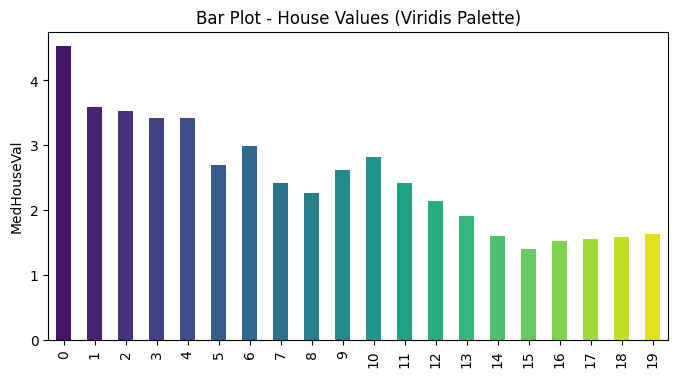

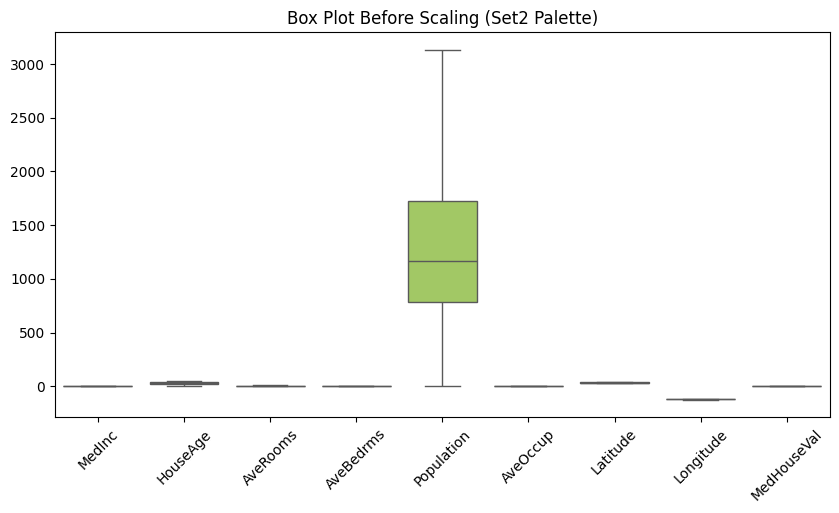

In [ ]:
# Bar Plot
plt.figure(figsize=(8, 4))
df["MedHouseVal"].head(20).plot(kind="bar", color=sns.color_palette("viridis", 20))
plt.title("Bar Plot - House Values (Viridis Palette)")
plt.ylabel("MedHouseVal")
plt.show()

# Box Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=original.select_dtypes(include=np.number), palette="Set2")
plt.title("Box Plot Before Scaling (Set2 Palette)")
plt.xticks(rotation=45)
plt.show()

## 5. Visualizations: Histograms Before & After Scaling

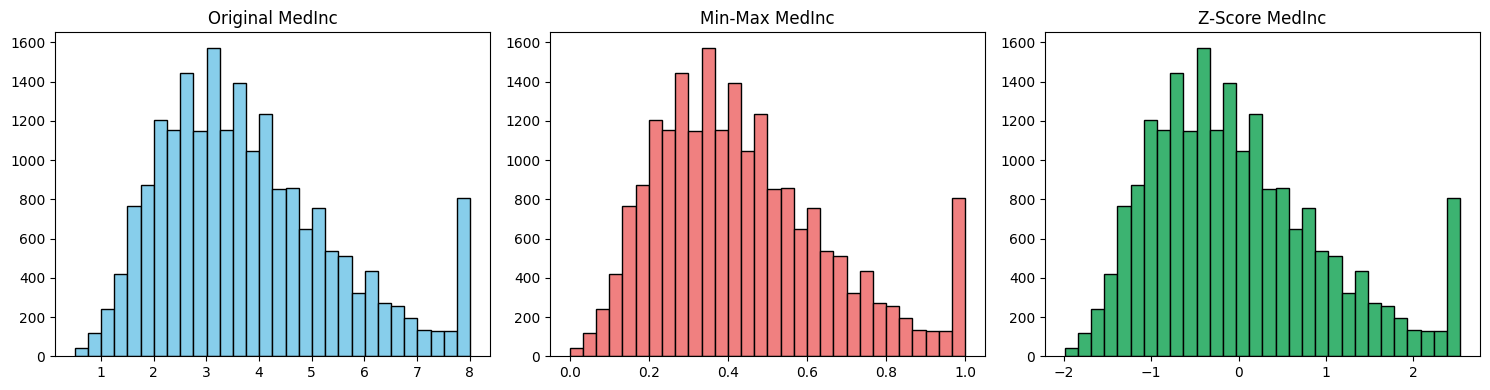

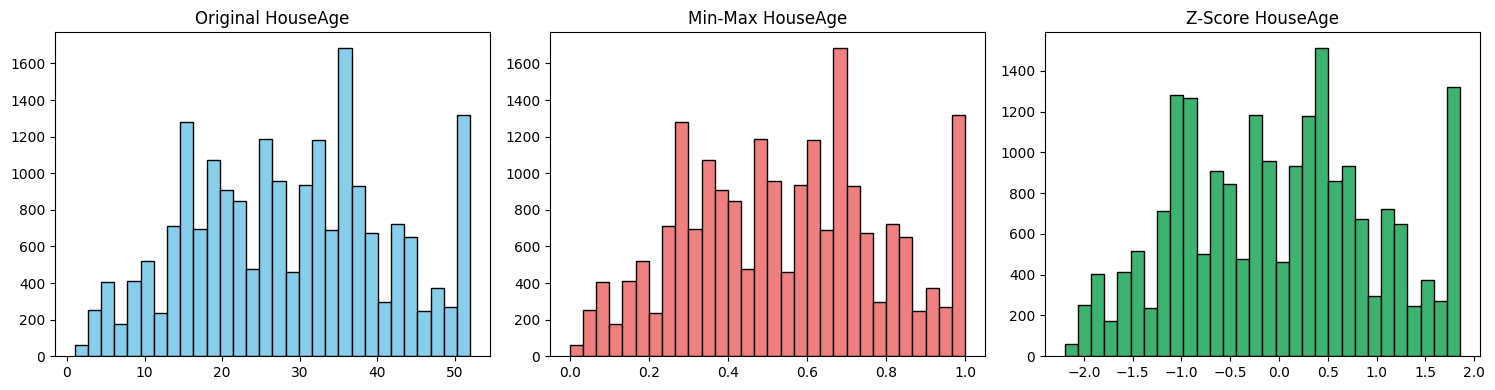

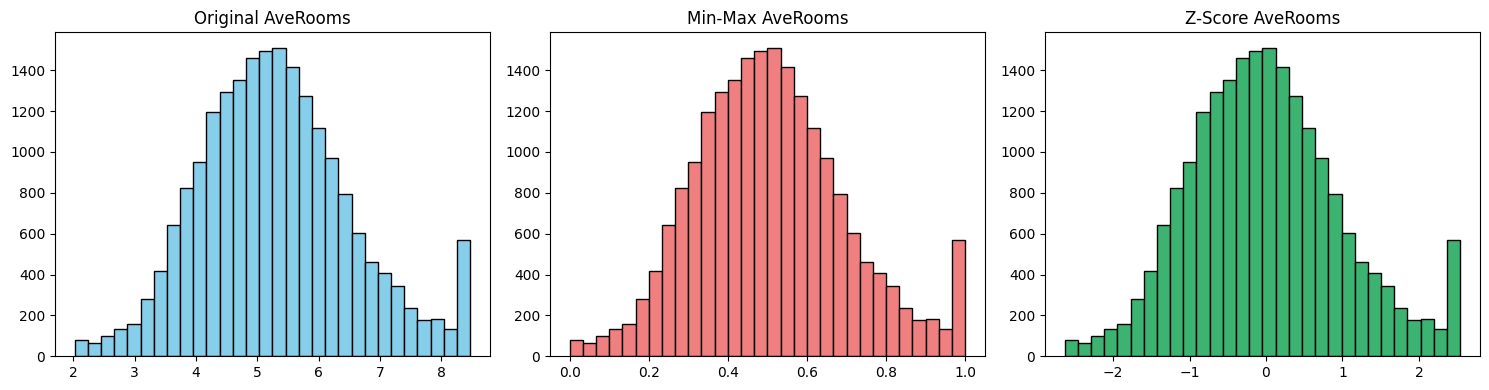

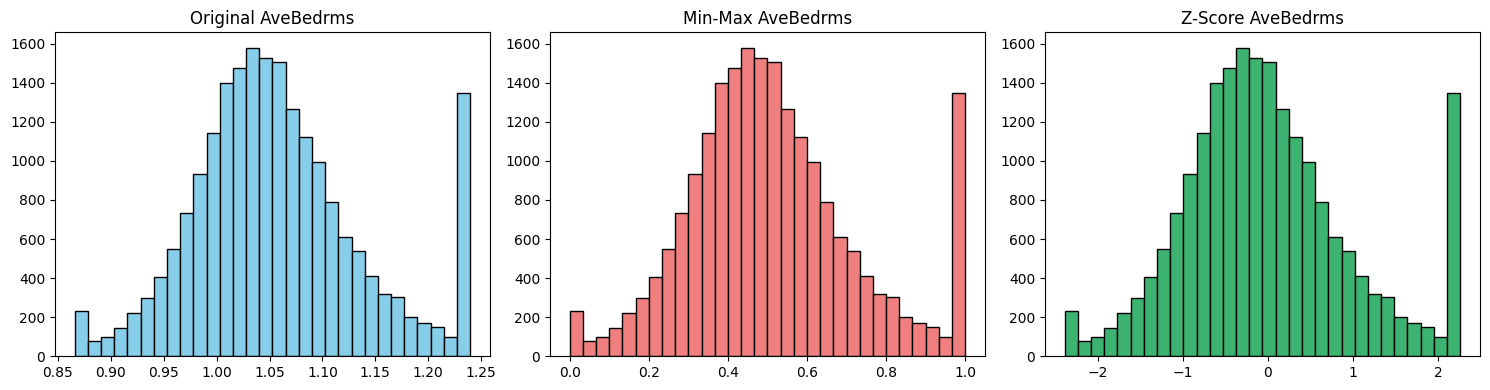

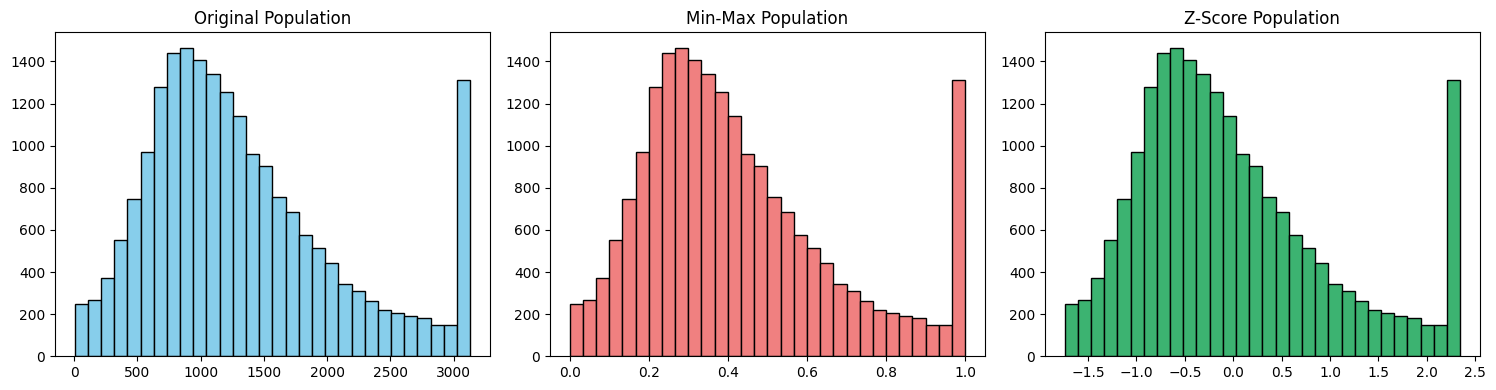

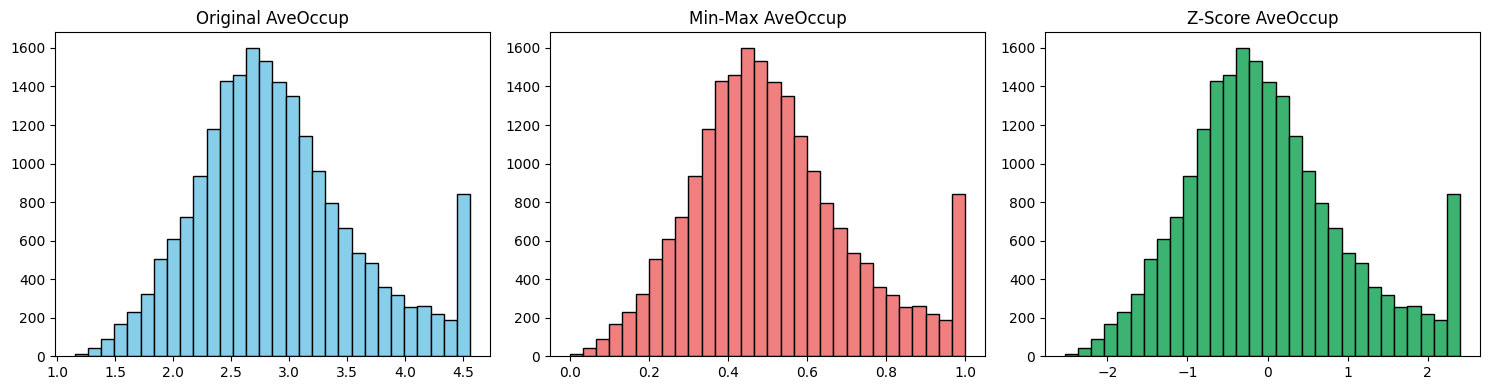

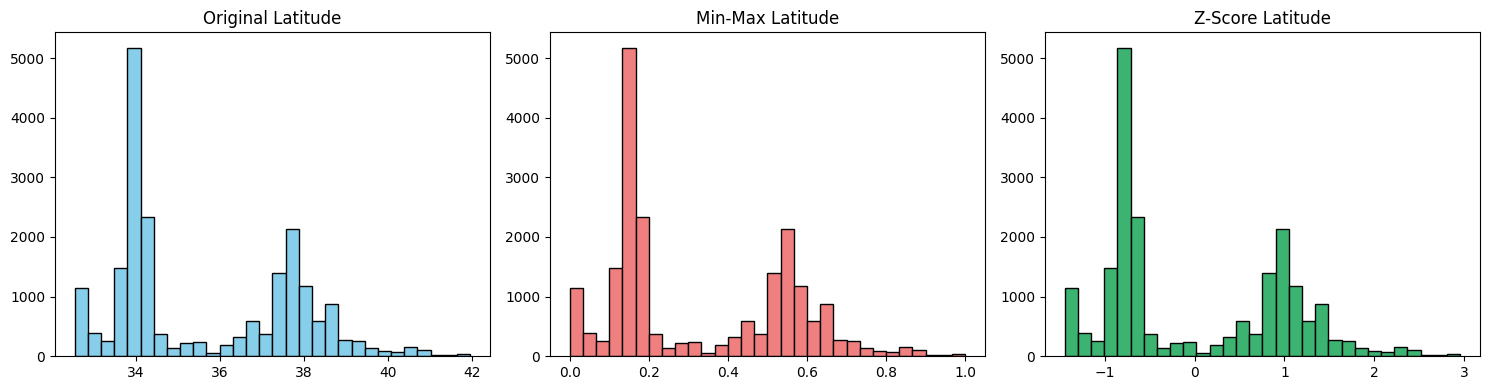

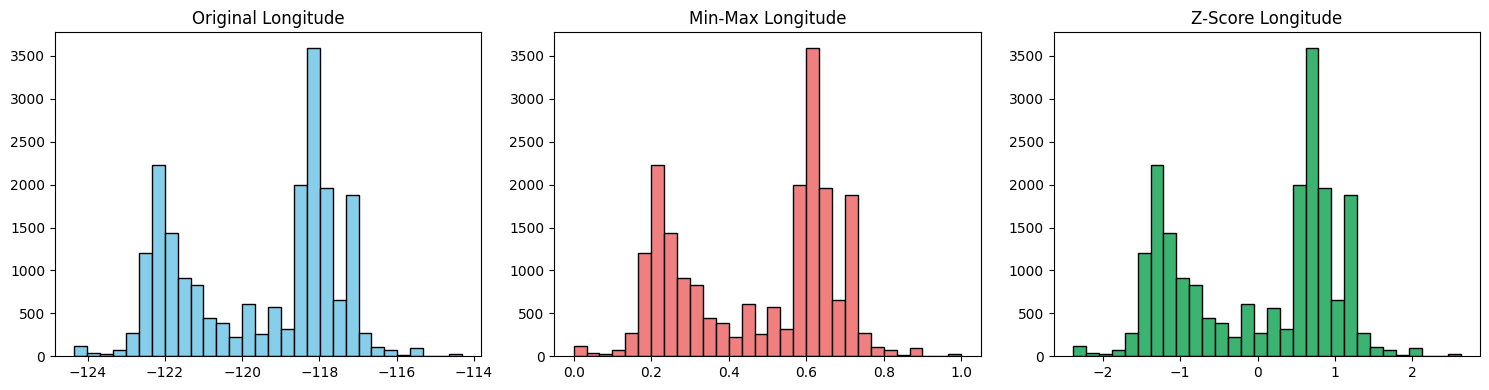

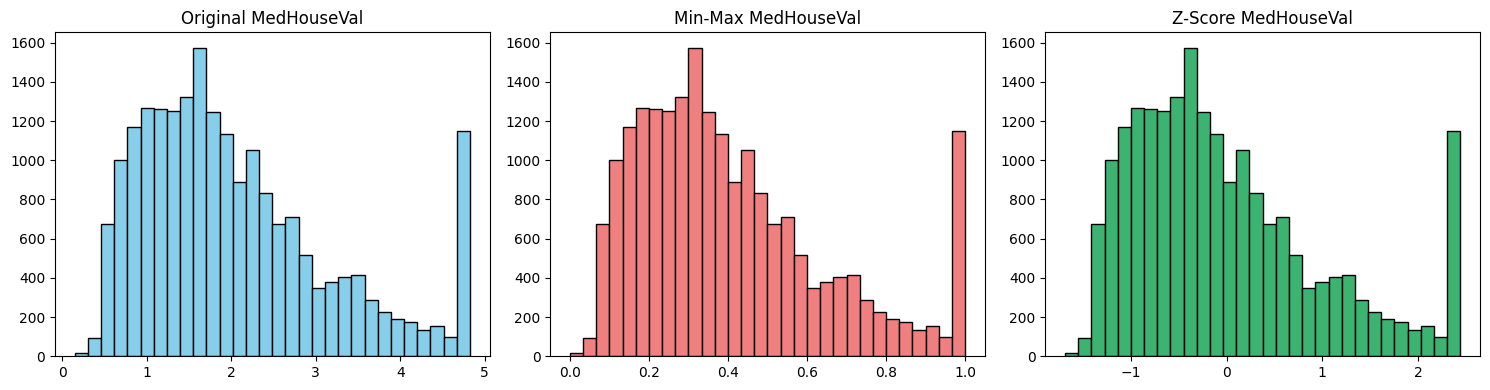

In [ ]:
for col in df.columns:
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.hist(original[col], bins=30, color="skyblue", edgecolor="black")
    plt.title("Original " + col)

    plt.subplot(1, 3, 2)
    plt.hist(df_minmax[col], bins=30, color="lightcoral", edgecolor="black")
    plt.title("Min-Max " + col)

    plt.subplot(1, 3, 3)
    plt.hist(df_standard[col], bins=30, color="mediumseagreen", edgecolor="black")
    plt.title("Z-Score " + col)

    plt.tight_layout()
    plt.show()

## 6. Visualizations: Scatter Plots Before & After Scaling

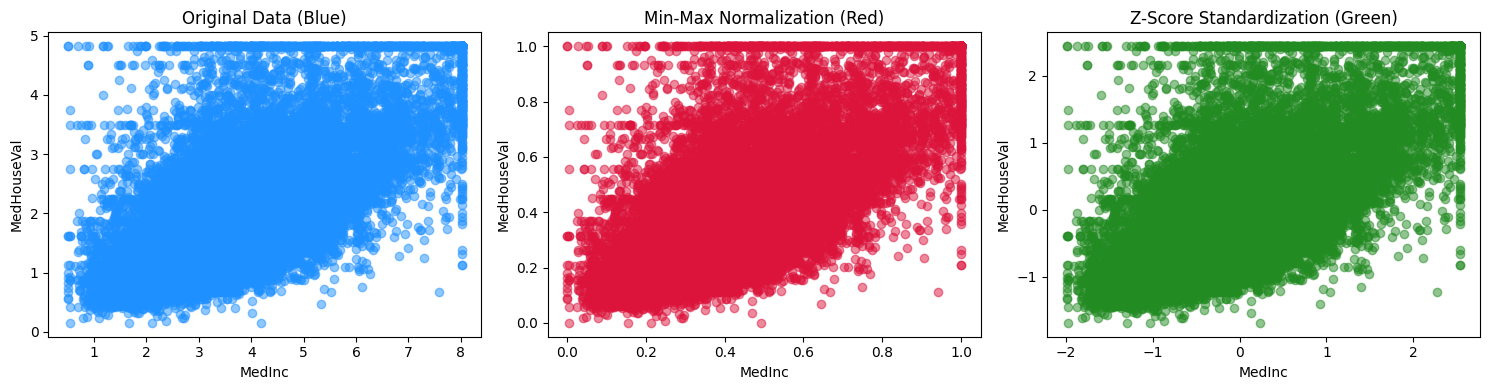

In [ ]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(original["MedInc"], original["MedHouseVal"], color="dodgerblue", alpha=0.5)
plt.title("Original Data (Blue)")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")

plt.subplot(1, 3, 2)
plt.scatter(df_minmax["MedInc"], df_minmax["MedHouseVal"], color="crimson", alpha=0.5)
plt.title("Min-Max Normalization (Red)")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")

plt.subplot(1, 3, 3)
plt.scatter(df_standard["MedInc"], df_standard["MedHouseVal"], color="forestgreen", alpha=0.5)
plt.title("Z-Score Standardization (Green)")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")

plt.tight_layout()
plt.show()

## 7. Save Datasets

In [ ]:
df.to_csv("cleaned_housing.csv", index=False)
df_minmax.to_csv("minmax_housing.csv", index=False)
df_standard.to_csv("standardized_housing.csv", index=False)

print("Preprocessing completed successfully! Files saved.")

Preprocessing completed successfully! Files saved.


# Iris Dataset Exploratory Data Analysis (EDA)
We will now load the classic Iris dataset and create the various visualizations requested (bar, stacked bar, line, scatter, bubble, histogram, box plot, heatmap, radar, pie, tree map, and word cloud) to extract deep insights from the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame
# Rename columns for ease of use
df_iris.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
# Add species names
species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
df_iris['species'] = df_iris['target'].map(species_map)

display(df_iris.head())
print(df_iris.info())

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


### 1. Bar Plot & Stacked Bar Plot
We will visualize the mean measurements of each iris feature across the different species using standard and stacked bar charts.

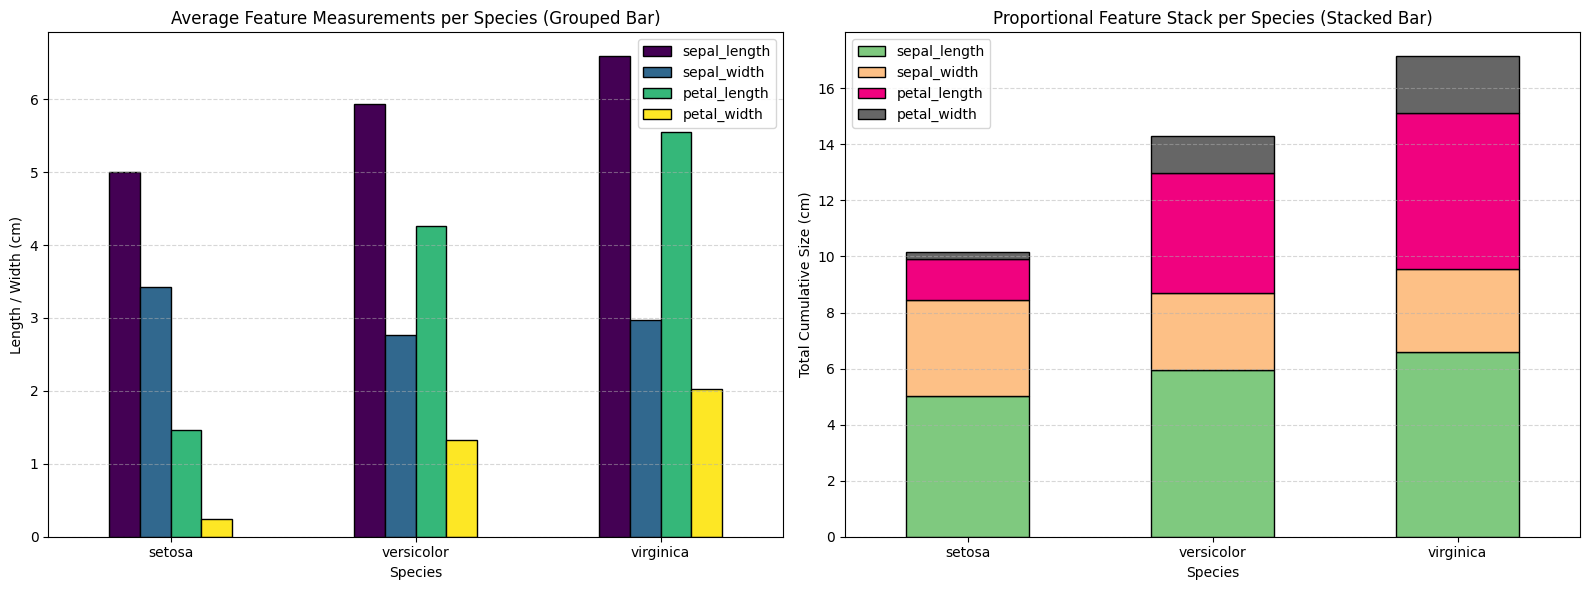

In [ ]:
# Compute means by species
species_means = df_iris.groupby('species')[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grouped Bar Plot
species_means.plot(kind='bar', ax=axes[0], colormap='viridis', edgecolor='black')
axes[0].set_title('Average Feature Measurements per Species (Grouped Bar)')
axes[0].set_ylabel('Length / Width (cm)')
axes[0].set_xlabel('Species')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Stacked Bar Plot
species_means.plot(kind='bar', stacked=True, ax=axes[1], colormap='Accent', edgecolor='black')
axes[1].set_title('Proportional Feature Stack per Species (Stacked Bar)')
axes[1].set_ylabel('Total Cumulative Size (cm)')
axes[1].set_xlabel('Species')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 2. Line Plot & Scatter Plot
We will inspect trends using a line plot of individual features and investigate relationships using a scatter plot.

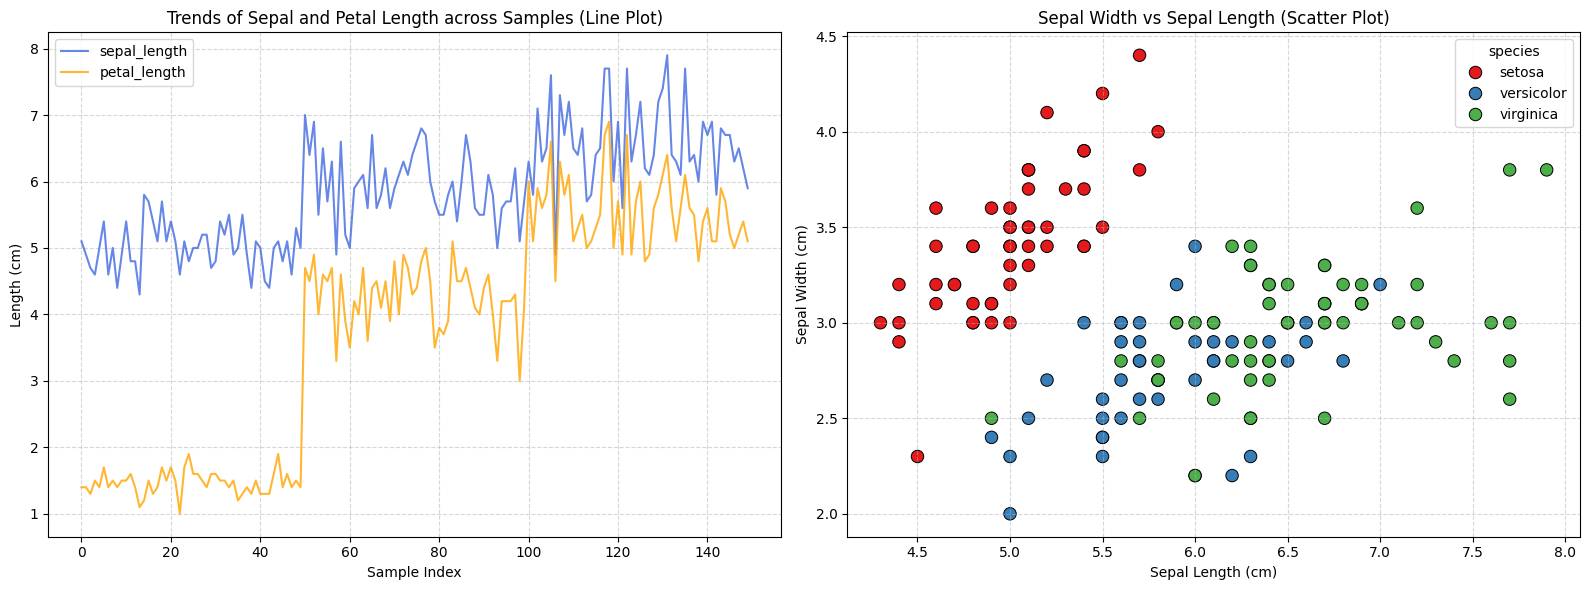

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Line Plot
df_iris[['sepal_length', 'petal_length']].plot(ax=axes[0], alpha=0.8, color=['royalblue', 'orange'])
axes[0].set_title('Trends of Sepal and Petal Length across Samples (Line Plot)')
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('Length (cm)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Scatter Plot
sns.scatterplot(data=df_iris, x='sepal_length', y='sepal_width', hue='species', palette='Set1', ax=axes[1], s=80, edgecolor='black')
axes[1].set_title('Sepal Width vs Sepal Length (Scatter Plot)')
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 3. Bubble Plot & Histograms
Bubble plots represent size metrics using dot dimensions, while histograms reveal value distributions.

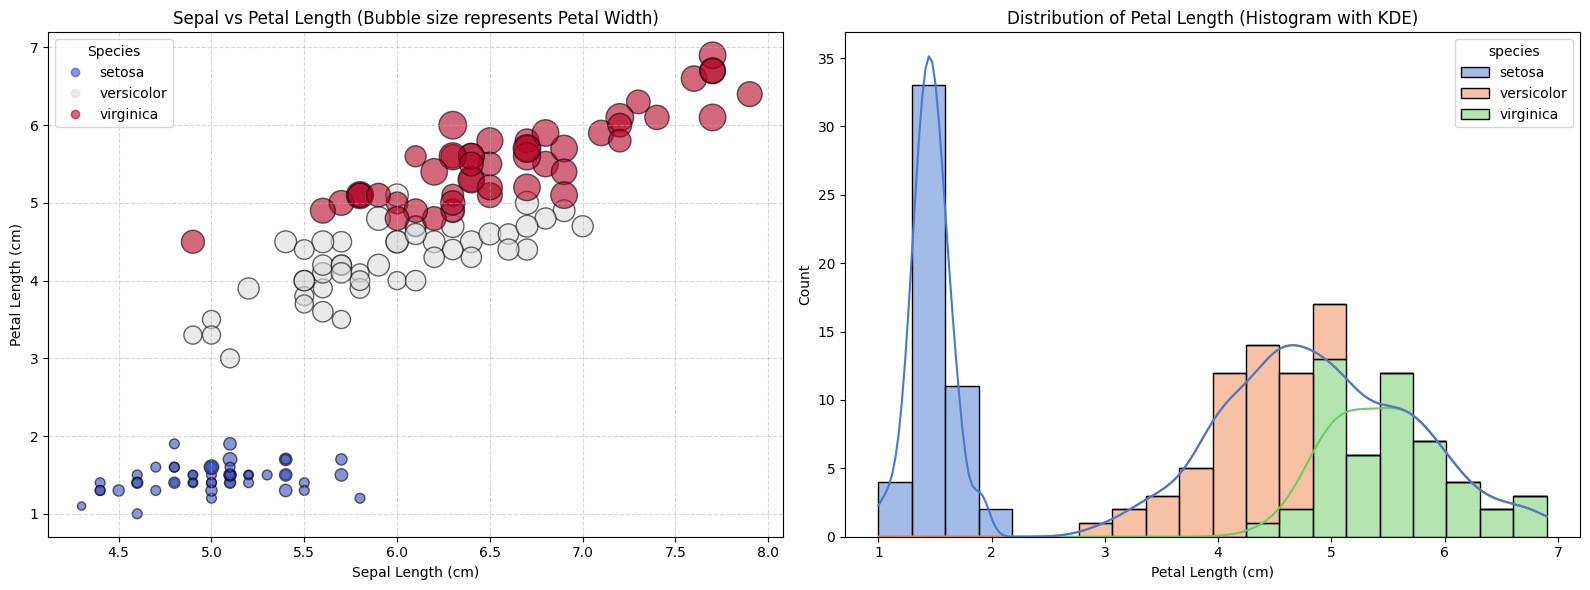

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bubble Plot: Bubble size corresponds to petal_width
bubble_sizes = df_iris['petal_width'] * 150 + 20
scatter = axes[0].scatter(df_iris['sepal_length'], df_iris['petal_length'],
                           s=bubble_sizes, c=df_iris['target'], cmap='coolwarm',
                           alpha=0.6, edgecolors='black')
axes[0].set_title('Sepal vs Petal Length (Bubble size represents Petal Width)')
axes[0].set_xlabel('Sepal Length (cm)')
axes[0].set_ylabel('Petal Length (cm)')
axes[0].grid(True, linestyle='--', alpha=0.5)
# Simple legend representing species color mappings
handles, labels = scatter.legend_elements(prop="colors")
axes[0].legend(handles, species_map.values(), title="Species")

# Histogram of Petal Lengths across Species
sns.histplot(data=df_iris, x='petal_length', hue='species', kde=True, bins=20, multiple='stack', palette='muted', ax=axes[1], edgecolor='black')
axes[1].set_title('Distribution of Petal Length (Histogram with KDE)')
axes[1].set_xlabel('Petal Length (cm)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### 4. Box Plot & Heatmap
Box plots show feature quartiles and identify potential outliers. The Heatmap helps to analyze correlation matrices.

/tmp/ipykernel_3645/2534284356.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_iris, x='species', y='sepal_width', palette='pastel', ax=axes[0], width=0.5)


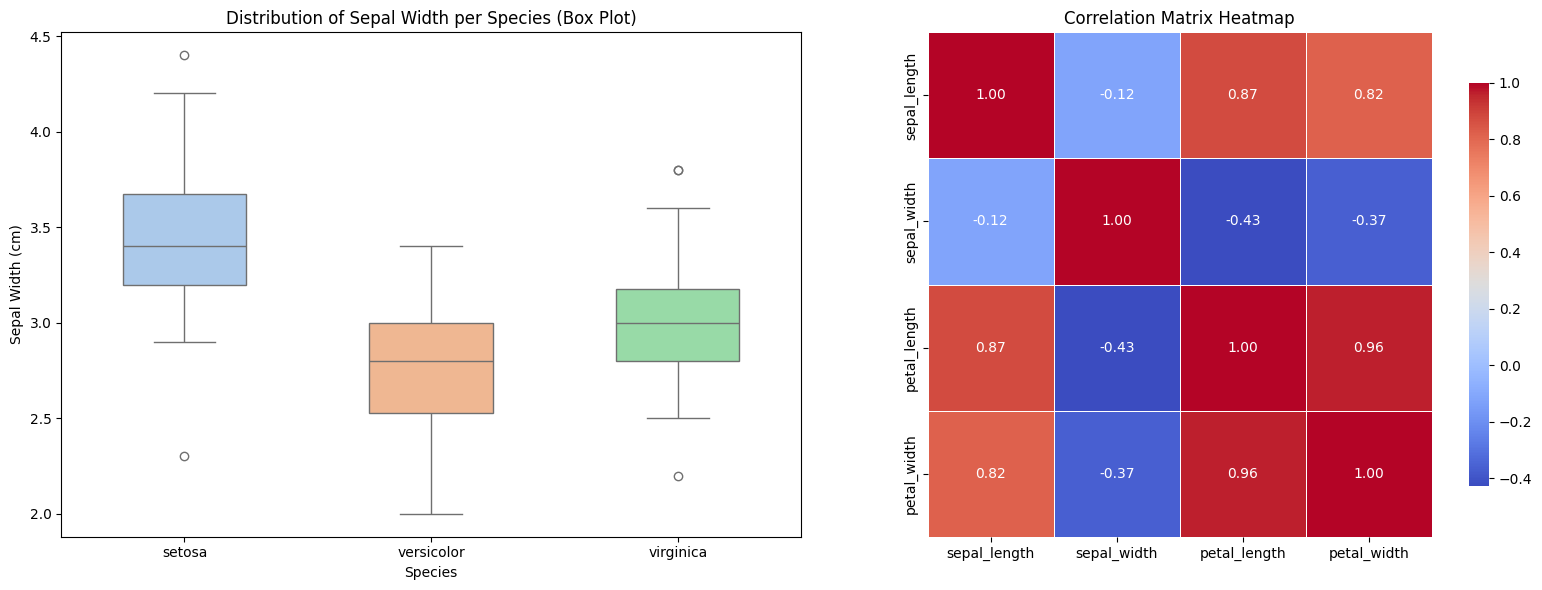

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box Plot
sns.boxplot(data=df_iris, x='species', y='sepal_width', palette='pastel', ax=axes[0], width=0.5)
axes[0].set_title('Distribution of Sepal Width per Species (Box Plot)')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Sepal Width (cm)')

# Heatmap of correlation matrix
corr_matrix = df_iris.iloc[:, :4].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1], square=True, cbar_kws={'shrink': .8})
axes[1].set_title('Correlation Matrix Heatmap')

plt.tight_layout()
plt.show()

### 5. Radar Chart (Polar Chart)
We will plot a radar chart to compare the multivariate profile of each Iris species.

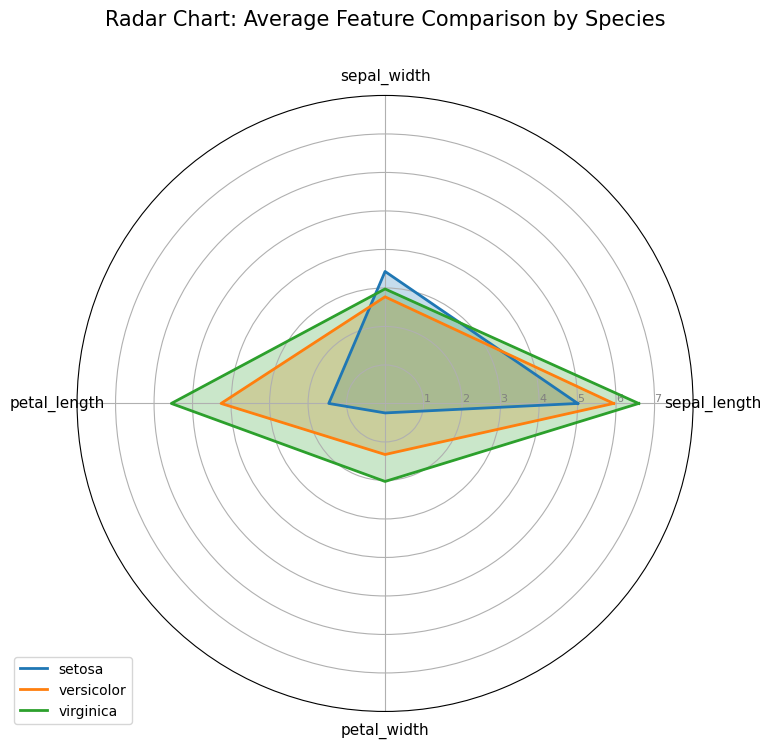

In [ ]:
categories = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
N = len(categories)

# Compute angles for the circle radar chart
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # complete the loop

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

# Add the feature labels
plt.xticks(angles[:-1], categories, size=11)
ax.set_rlabel_position(0)
plt.yticks([1, 2, 3, 4, 5, 6, 7], ["1", "2", "3", "4", "5", "6", "7"], color="grey", size=8)
plt.ylim(0, 8)

# Plot each species
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for idx, species in enumerate(species_map.values()):
    values = species_means.loc[species].values.flatten().tolist()
    values += values[:1] # complete loop

    ax.plot(angles, values, linewidth=2, linestyle='solid', label=species, color=colors[idx])
    ax.fill(angles, values, color=colors[idx], alpha=0.25)

plt.title('Radar Chart: Average Feature Comparison by Species', size=15, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()

### 6. Pie Chart & Treemap
We will examine class distribution proportions using Pie and Treemap structures.

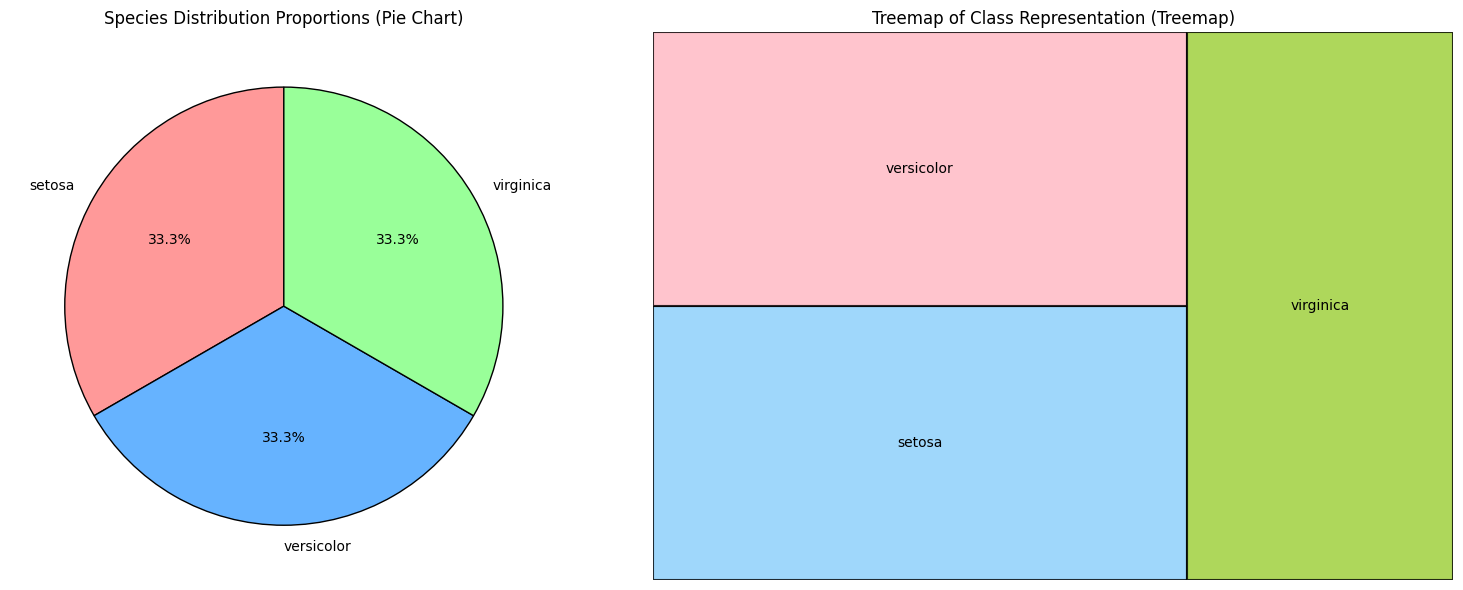

In [ ]:
import squarify # squarify is used to draw treemaps in matplotlib

# Count species frequencies
species_counts = df_iris['species'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pie Chart
species_counts.plot(kind='pie', autopct='%1.1f%%', ax=axes[0], colors=['#ff9999','#66b3ff','#99ff99'],
                    wedgeprops={'edgecolor': 'black', 'linewidth': 1}, startangle=90)
axes[0].set_title('Species Distribution Proportions (Pie Chart)')
axes[0].set_ylabel('')

# Treemap
squarify.plot(sizes=species_counts.values, label=species_counts.index,
              color=['lightskyblue', 'lightpink', 'yellowgreen'], alpha=0.8, ax=axes[1], edgecolor='black', linewidth=1.5)
axes[1].set_title('Treemap of Class Representation (Treemap)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### 7. Word Cloud
Finally, we will generate a word cloud utilizing labels derived dynamically from feature significance and statistical relationships within the Iris dataset.

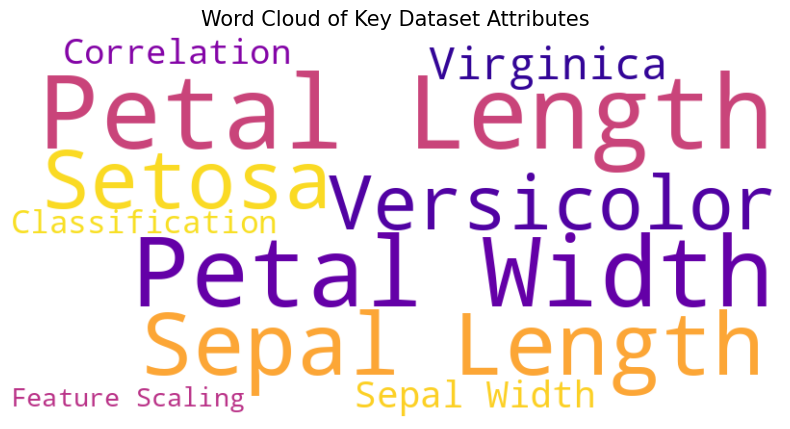

In [ ]:
from wordcloud import WordCloud

# Creating text based on feature correlation strength and attributes
words_dict = {
    'Petal Length': 100,
    'Petal Width': 90,
    'Sepal Length': 70,
    'Setosa': 60,
    'Versicolor': 60,
    'Virginica': 60,
    'Sepal Width': 40,
    'Classification': 30,
    'Correlation': 35,
    'Feature Scaling': 25
}

wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='plasma').generate_from_frequencies(words_dict)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Key Dataset Attributes', size=15)
plt.show()

# Stock Market Time-Series Analysis
We will fetch real-world stock data using `yfinance` and create comprehensive time-series visualizations, including Candlestick charts, moving average overlays (SMA & EMA), Bollinger Bands for volatility, and volume analysis.

In [ ]:
!pip install yfinance -q

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from datetime import datetime, timedelta

ticker = 'AAPL'
end_date = datetime.now()
start_date = end_date - timedelta(days=180)

try:
    df_stock = yf.download(ticker, start=start_date, end=end_date)
    if isinstance(df_stock.columns, pd.MultiIndex):
        df_stock.columns = df_stock.columns.get_level_values(0)

    # Calculate indicators
    df_stock['SMA_20'] = df_stock['Close'].rolling(window=20).mean()
    df_stock['EMA_20'] = df_stock['Close'].ewm(span=20, adjust=False).mean()

    std_20 = df_stock['Close'].rolling(window=20).std()
    df_stock['BB_Upper'] = df_stock['SMA_20'] + (std_20 * 2)
    df_stock['BB_Lower'] = df_stock['SMA_20'] - (std_20 * 2)

    print(f"Successfully fetched stock data for {ticker}. DataFrame shape: {df_stock.shape}")
    display(df_stock.tail())
except Exception as e:
    print(f"An error occurred while fetching stock data: {e}")

/tmp/ipykernel_1650/1329020794.py:14: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed

Successfully fetched stock data for AAPL. DataFrame shape: (124, 9)


Price,Close,High,Low,Open,Volume,SMA_20,EMA_20,BB_Upper,BB_Lower
Date,,,,,,,,,
2026-11-11,355.359985,355.639772,349.064750,349.284585,34453500,344.604166,344.281120,354.738729,334.469603
2026-11-12,354.880005,359.369995,354.410004,357.809998,31875000,345.261150,345.290537,356.279108,334.243191
2026-11-13,356.269989,360.829987,355.750000,357.959991,40027500,345.914688,346.336199,357.923711,333.905665
2026-11-16,352.779999,357.130005,351.309998,357.130005,50292200,346.419707,346.949894,358.702300,334.137113
2026-11-17,351.910004,355.359985,349.670013,352.829987,37341600,347.053094,347.422286,359.081122,335.025067


### 1. Interactive Candlestick Chart with SMA, EMA, and Bollinger Bands
We use Plotly to construct an interactive candlestick chart overlaying these indicators for volatility and trend analysis.

In [ ]:
import plotly.graph_objects as go

fig = go.Figure()

# Candlestick chart
fig.add_trace(go.Candlestick(
    x=df_stock.index,
    open=df_stock['Open'],
    high=df_stock['High'],
    low=df_stock['Low'],
    close=df_stock['Close'],
    name='Candlestick'
))

# Add SMA and EMA
fig.add_trace(go.Scatter(x=df_stock.index, y=df_stock['SMA_20'], name='20-day SMA', line=dict(color='orange', width=1.5)))
fig.add_trace(go.Scatter(x=df_stock.index, y=df_stock['EMA_20'], name='20-day EMA', line=dict(color='blue', width=1.5)))

# Add Bollinger Bands
fig.add_trace(go.Scatter(x=df_stock.index, y=df_stock['BB_Upper'], name='Bollinger Upper', line=dict(color='gray', width=1, dash='dash')))
fig.add_trace(go.Scatter(x=df_stock.index, y=df_stock['BB_Lower'], name='Bollinger Lower', line=dict(color='gray', width=1, dash='dash'), fill='tonexty', fillcolor='rgba(128, 128, 128, 0.1)'))

fig.update_layout(
    title=f'{ticker} Candlestick Chart with Technical Indicators',
    yaxis_title='Stock Price (USD)',
    xaxis_title='Date',
    xaxis_rangeslider_visible=False,
    template='plotly_white'
)

fig.show()

### 2. Trading Volume Trend Plot
Volume plots help check the strength of price movements and identify significant breakout events.

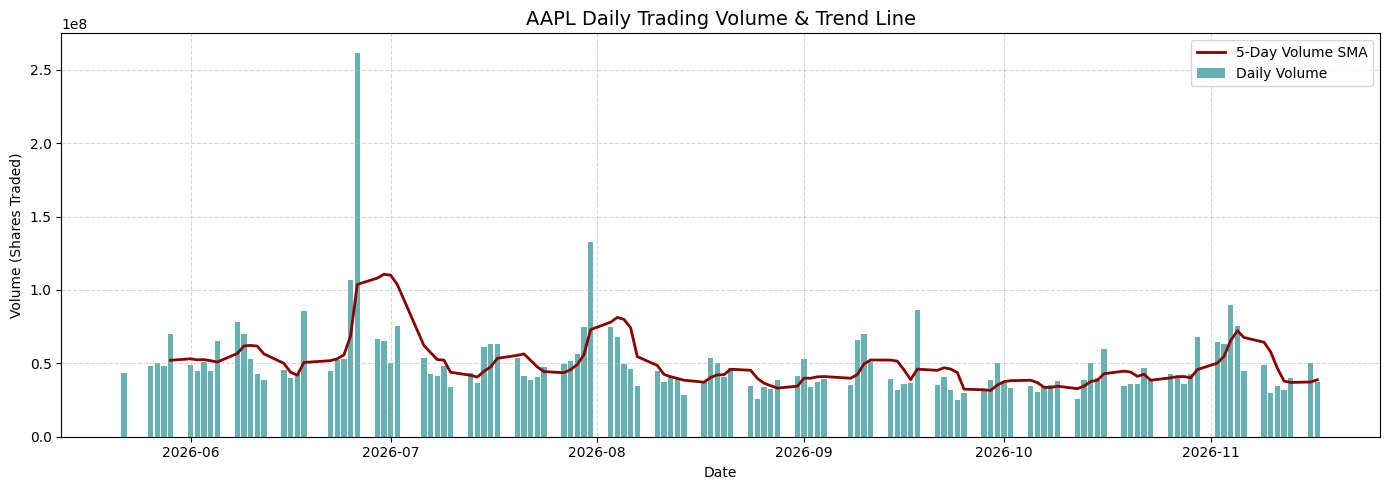

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
# Plot volume with a 5-day moving average to smooth short term noise
plt.bar(df_stock.index, df_stock['Volume'], color='teal', alpha=0.6, label='Daily Volume')
plt.plot(df_stock.index, df_stock['Volume'].rolling(5).mean(), color='darkred', label='5-Day Volume SMA', linewidth=2)

plt.title(f'{ticker} Daily Trading Volume & Trend Line', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Volume (Shares Traded)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Stock Market Time-Series Interpretation

### 1. Trends & Moving Average Overlays
* **SMA vs EMA**: The 20-day Exponential Moving Average (EMA) reacts quicker to recent price fluctuations than the Simple Moving Average (SMA), pointing out rapid momentum shifts.
* **Trend Identification**: When the stock price remains consistently above both the SMA and EMA, it confirms an established uptrend, while trading below indicates a downtrend.

### 2. Volatility Analysis (Bollinger Bands)
* **Band Width**: The distance between the Upper and Lower Bollinger Bands represents rolling market volatility. Narrow bands indicate periods of consolidation, whereas expanding bands denote high volatility.
* **Price Boundaries**: Touching or exceeding the outer bands often points to overextended conditions (overbought near upper band, oversold near lower band) preceding potential reversals.

### 3. Volume and Sentiment
* **Volume Trends**: Strong price movements accompanied by spikes in daily volume (rising above the 5-day volume SMA line) validate the strength of the breakout or trend direction. Low volume trends indicate weak market conviction.